Base de dados de treinamento de modelo preditivo para predição de risco do paciente(risk_score):

In [1]:
import numpy as np
import pandas as pd

np.random.seed(42)
n = 5000

df = pd.DataFrame({
    "idade_media": np.random.normal(55, 12, n).clip(18, 90),
    "carga_sistema": np.random.uniform(30, 100, n),
    "tempo_espera": np.random.normal(45, 20, n).clip(5, 180),
    "fc_media": np.random.normal(85, 15, n).clip(50, 150),
    "spo2_media": np.random.normal(95, 3, n).clip(70, 100),
    "pa_sistolica": np.random.normal(125, 20, n).clip(80, 200),
    "temperatura": np.random.normal(24, 5, n).clip(10, 40),
    "densidade_eventos": np.random.poisson(3, n),
    "eventos_24h": np.random.poisson(2, n),
    "disponibilidade_recursos": np.random.uniform(20, 100, n)
})

risk_score = (
    (df["carga_sistema"] > 80).astype(int) +
    (df["tempo_espera"] > 60).astype(int) +
    (df["spo2_media"] < 92).astype(int) +
    (df["fc_media"] > 110).astype(int) +
    (df["eventos_24h"] > 4).astype(int) +
    (df["disponibilidade_recursos"] < 40).astype(int)
)

df["pico_risco"] = (risk_score >= 2).astype(int)

Base de conhecimento contendo protocolos médicos:

In [2]:
protocolos = [
    "Se SPO2 < 88% → iniciar suporte respiratório imediato",
    "Se carga do sistema > 85% → abrir unidades temporárias",
    "Se FC > 120 → iniciar monitoramento intensivo",
    "Se eventos_24h > 5 → ativar equipe de resposta rápida",
    "Se disponibilidade_recursos < 30% → redistribuir insumos",
    "Se tempo_espera > 90 min → priorizar triagem emergencial",
    "Se temperatura > 38°C média → iniciar protocolo infeccioso",
    "Se densidade_eventos > 6 → ativar plano de contingência",
    "Se PA sistólica < 90 → iniciar protocolo de choque",
    "Se risco sistêmico alto → ativar estado de emergência"
]

Treinando o modelo RandomForestClassifier:

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
import joblib

# 1. Dado (X) do que é o objetivo prever (y)
X = df.drop("pico_risco", axis=1) # As colunas dos sinais vitais
y = df["pico_risco"]              # A coluna que diz se tem pico de risco (0 ou 1)

# 2. Dividindo em dados de Treino (80%) e Teste (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Instanciar e Treinar o modelo
modelo = RandomForestClassifier(random_state=42)
modelo.fit(X_train, y_train)

# 4. Avaliando o desempenho do modelo
y_pred = modelo.predict(X_test)
print("=== AVALIAÇÃO DO MODELO ===")
print(f"Acurácia: {accuracy_score(y_test, y_pred):.2f}")
print("Matriz de Confusão:\n", confusion_matrix(y_test, y_pred))

=== AVALIAÇÃO DO MODELO ===
Acurácia: 1.00
Matriz de Confusão:
 [[744   1]
 [  0 255]]


Para testar o seu sistema, simule dados de um novo paciente, como o exemplo a seguir:



In [4]:
# 1. Dados do novo paciente
novo_caso = pd.DataFrame([{
    "idade_media": 62,
    "carga_sistema": 92,
    "tempo_espera": 75,
    "fc_media": 118,
    "spo2_media": 89,
    "pa_sistolica": 100,
    "temperatura": 37.5,
    "densidade_eventos": 7,
    "eventos_24h": 5,
    "disponibilidade_recursos": 25
}])

# 2. Previsão de risco (pega a probabilidade da classe 1 - "pico_risco")
probabilidade_risco = modelo.predict_proba(novo_caso)[0][1]

# 3. Exibir resultado
print(f"RISCO PREVISTO: {probabilidade_risco:.2f}")

RISCO PREVISTO: 0.98


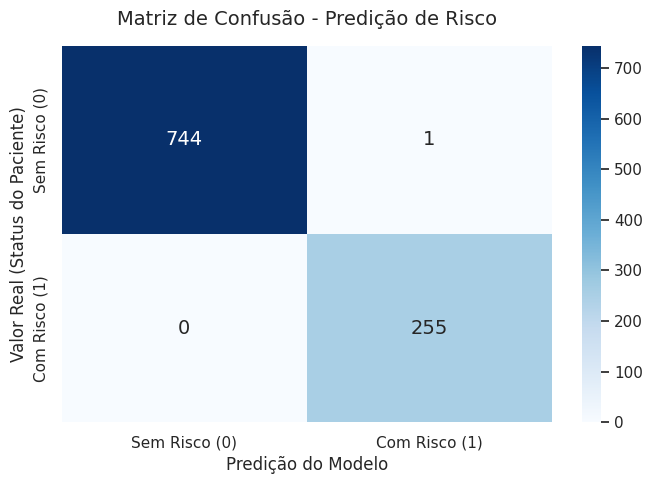

/tmp/ipykernel_3588/3092618263.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importancias[indices],


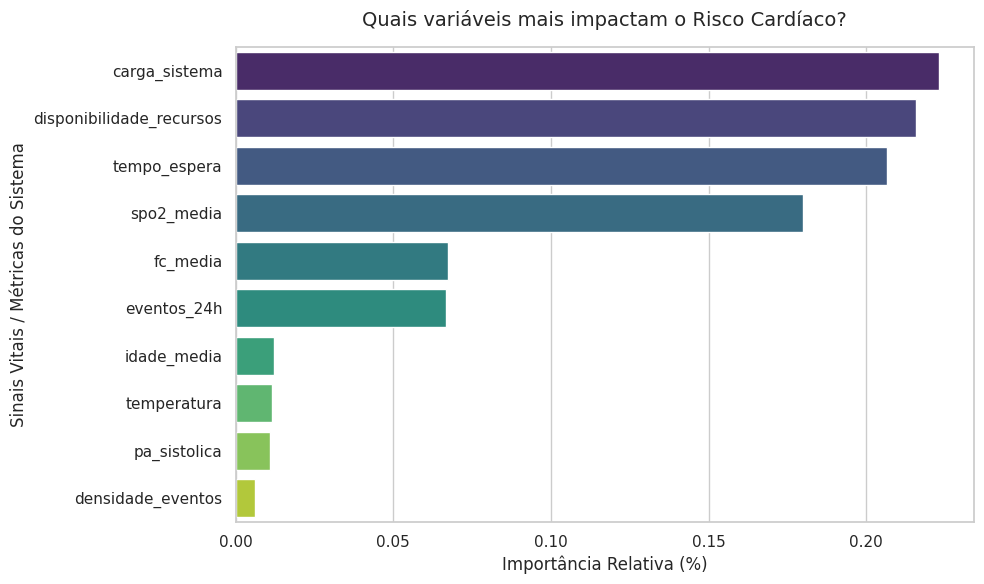

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Configuração visual dos gráficos
sns.set_theme(style="whitegrid")

# ==========================================
# GRÁFICO 1: Matriz de Confusão
# ==========================================
plt.figure(figsize=(7, 5))
cm = confusion_matrix(y_test, y_pred)

# Criando o Heatmap
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Sem Risco (0)', 'Com Risco (1)'],
            yticklabels=['Sem Risco (0)', 'Com Risco (1)'],
            annot_kws={"size": 14}) # Aumenta o tamanho da fonte dos números

plt.title('Matriz de Confusão - Predição de Risco', fontsize=14, pad=15)
plt.ylabel('Valor Real (Status do Paciente)', fontsize=12)
plt.xlabel('Predição do Modelo', fontsize=12)
plt.tight_layout()
plt.show()

# ==========================================
# GRÁFICO 2: Importância das Variáveis
# ==========================================
plt.figure(figsize=(10, 6))

# Extraindo a importância de cada coluna do modelo RandomForest
importancias = modelo.feature_importances_
indices = np.argsort(importancias)[::-1]
nomes_features = X.columns

# Criando o gráfico de barras horizontais
sns.barplot(x=importancias[indices],
            y=[nomes_features[i] for i in indices],
            palette='viridis')

plt.title('Quais variáveis mais impactam o Risco Cardíaco?', fontsize=14, pad=15)
plt.xlabel('Importância Relativa (%)', fontsize=12)
plt.ylabel('Sinais Vitais / Métricas do Sistema', fontsize=12)
plt.tight_layout()
plt.show()

Salvando o Modelo

In [6]:
joblib.dump(modelo, 'modelo_risco.pkl')
print("\nModelo salvo com sucesso como 'modelo_risco.pkl'!")


Modelo salvo com sucesso como 'modelo_risco.pkl'!
